# Steering a refinement

*Written by Claude Code, Anthropic's coding agent, for the rietx project.*

We take the fluorapatite refinement from notebook 02 and change what it refines.
First we tie three displacement parameters together.
Then we run a plan that frees two parameters the data cannot separate, go back in the history, and hold one of them.
By the end you can tie, go back and hold, and read the verdict rietx gives for a structure.

**You need** rietx 1.10 or later, which the next cell installs.
Notebook 02 introduces the first fit and how to read its parameters.

**The data** is `FAP.XRA` from the GSAS-II `LabData` tutorial, with a CIF transcribed from the same tutorial's experiment file.
Both ship with rietx.

**Runtime** is under 30 seconds on a laptop.

In [ ]:
%pip install rietx

## The starting fit

This cell repeats notebook 02's first refinement, which that notebook reads line by line.

In [1]:
import rietx as rx
from rietx.examples import examples_dir

data = rx.read_pattern(examples_dir() / "FAP.XRA")
structure = rx.Structure.from_cif(examples_dir() / "fluorapatite.cif")
instrument = rx.Instrument.bragg_brentano(radiation="CuKa")
instrument.geometry.axial_sl.value = 0.02
instrument.geometry.axial_hl.value = 0.02
instrument.background = rx.BackgroundChebyshev.with_terms(6)

ref = rx.Refinement(structure, instrument)
result = ref.fit(data, plan="mccusker_structural", two_theta_limits=(15, 130))
result.status

'converged'

## A constraint between three atoms

Fluorapatite has three oxygen sites in its phosphate group: O5, O6 and O7.
Their Biso values are expected to be similar.
Check that against the data before constraining anything.

In [2]:
OXYGENS = ["phases.0.atoms.4.biso", "phases.0.atoms.5.biso", "phases.0.atoms.6.biso"]
[result.parameter(path) for path in OXYGENS]

[phases.0.atoms.4.biso  0.24(15)  vary,
 phases.0.atoms.5.biso  0.47(16)  vary,
 phases.0.atoms.6.biso  0.36(11)  vary]

Each value lies within about one esd of the others.
The data cannot tell them apart, so one shared value loses nothing and spends two fewer parameters.
`tie_equal` makes the second and third follow the first.
Refit with the same plan, so the tie is the only difference from the first fit.

In [3]:
ref.tie_equal(OXYGENS)
tied = ref.fit(data, plan="mccusker_structural", two_theta_limits=(15, 130))
[tied.parameter(path) for path in OXYGENS]

[phases.0.atoms.4.biso  0.360(79)  vary,
 phases.0.atoms.5.biso  0.360(79)  tied,
 phases.0.atoms.6.biso  0.360(79)  tied]

The three rows now carry one value, and two of them read `tied`.
The shared esd is smaller than any of the three separate ones.
Rwp says little about a constraint.
Judge one by its premise and its esds.
[How to tie parameters together](https://rietx.org/docs/stable/guides/tie.html#check-that-the-data-allow-the-tie) shows the check in full.

## Two parameters the data cannot separate

A flat-plate diffractometer has two corrections that shift every peak.
The zero shift is constant in 2θ, and the specimen displacement goes as cos θ.
The `lab_bragg_brentano` plan frees both.
Run it from where the tied fit ended, and expect a warning about the pair.

In [4]:
SHIFTS = ["instrument.zero_shift", "instrument.geometry.sample_displacement", "phases.0.cell.a"]
both = ref.fit(data, plan="lab_bragg_brentano", two_theta_limits=(15, 130))
[both.parameter(path) for path in SHIFTS]

[instrument.zero_shift  -0.164(38)  vary,
 instrument.geometry.sample_displacement  -0.230(68)  vary,
 phases.0.cell.a  9.3690(10)  vary]

Each correction refined to several esds from zero.
Ask the diagnostics which pairs they found correlated with the zero shift.

In [5]:
[d for d in both.diagnostics if d.code == "HIGH_CORRELATION" and "instrument.zero_shift" in d.where]

[warning[HIGH_CORRELATION]: Correlated pair: instrument.zero_shift ~ instrument.geometry.sample_displacement (ρ=+1.000). Flagged in stages: zero_disp, cell, profile_w, profile, lines_axial, roughness, closing.
  at: instrument.zero_shift, instrument.geometry.sample_displacement
  help: Fix one of the two at a known value, or free them in separate stages.,
 warning[HIGH_CORRELATION]: Correlated pair: phases.0.cell.a ~ instrument.zero_shift (ρ=+0.997). Flagged in stages: cell, profile_w, profile, lines_axial, roughness, closing.
  at: phases.0.cell.a, instrument.zero_shift
  help: Fix one of the two at a known value, or free them in separate stages.,
 warning[HIGH_CORRELATION]: Correlated pair: phases.0.cell.c ~ instrument.zero_shift (ρ=+0.995). Flagged in stages: cell, profile_w, profile, lines_axial, roughness, closing.
  at: phases.0.cell.c, instrument.zero_shift
  help: Fix one of the two at a known value, or free them in separate stages.]

The first warning says the zero shift and the displacement move together completely.
The fit could trade one against the other without changing the pattern, so neither value is a measurement.
The cell's a and c are correlated with the zero shift too.
[About correlations and esds](https://rietx.org/docs/stable/concepts/correlations.html#what-to-do-about-a-correlation) lists the ways out.

## Go back, and hold one of the pair

The cure is to hold one of the pair at a value known from outside this fit.
GSAS's own refinement of this file held the zero shift at 0 and refined the displacement.
We do the same.

Every fit committed its stages to the refinement's history.
`checkout` returns the working state to the tied fit's last node, tie included.
`set_values` puts the zero shift at 0, and `hold` keeps it there whatever the plan frees.

In [6]:
ref.checkout(tied.node_id)
ref.set_values({"instrument.zero_shift": 0.0})
ref.hold(["instrument.zero_shift"])

['instrument.zero_shift']

`hold` returns the paths it now holds.
Run the same plan again.

In [7]:
held = ref.fit(data, plan="lab_bragg_brentano", two_theta_limits=(15, 130))
[held.parameter(path) for path in SHIFTS[1:]]

[instrument.geometry.sample_displacement  0.0630(15)  vary,
 phases.0.cell.a  9.373322(81)  vary]

The list starts at the displacement, because a held parameter is not refined and the result has no row for it.
The displacement's esd and the cell's are both far smaller than they were with the pair free.

The plan still tried to free the zero shift, and the result says so.

In [8]:
[d for d in held.diagnostics if d.code == "HOLD_BLOCKED_PLAN"]

[info[HOLD_BLOCKED_PLAN]: 1 held parameter was matched by the turn_on glob of stages 'closing', 'zero_disp' and stayed fixed: instrument.zero_shift.
  at: instrument.zero_shift
  help: Call unhold() on them first if you meant the plan to refine them.]

Use `ref.hold` for this, and leave the parameter's `vary` flag alone.
A plan sets which parameters vary at each stage, so it would free a parameter marked `vary=False`.
A hold outranks the plan.
[How to keep a parameter fixed whatever the plan frees](https://rietx.org/docs/stable/guides/hold.html) covers releasing one too.

## The final structural fit

`lab_bragg_brentano` refines the profile and the instrument but leaves the atoms alone.
Refine the structure once more, with the zero shift held, the displacement as just measured, and the tie in place.

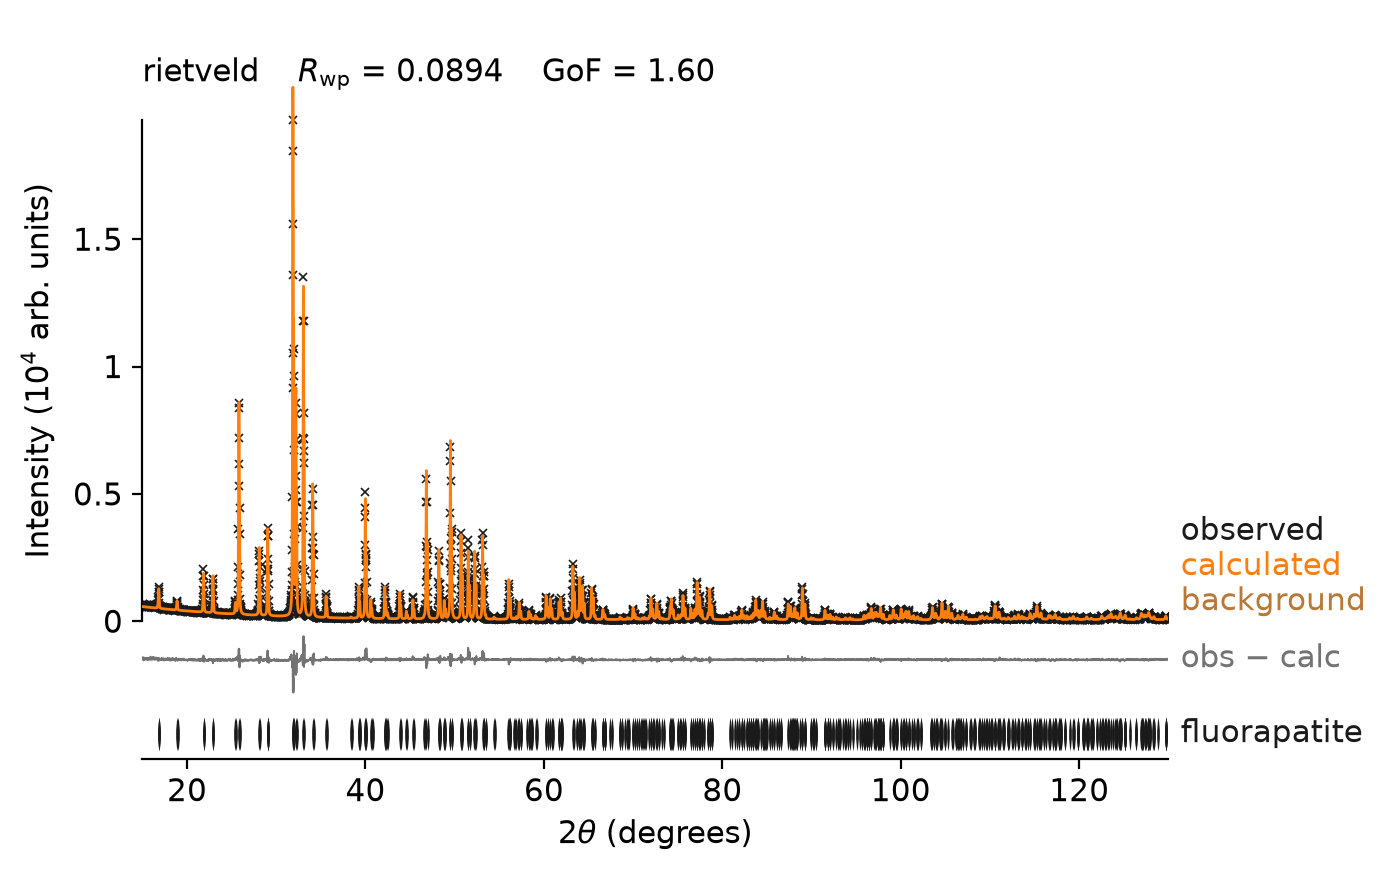

In [9]:
final = ref.fit(data, plan="mccusker_structural", two_theta_limits=(15, 130))
final.plot()

The difference curve looks as it did after notebook 02's first fit.
What changed is which numbers are measurements.
The displacement now has a usable esd, and the zero shift is a value we stated.

## The history

Every stage of every fit is a node you can return to.

In [10]:
ref.history

tcb8d2285  56 nodes  data=FAP.XRA
 n0000  root                   —
 n0001  stage:scale_bkg        Rwp 0.5704
 n0002  stage:zero             Rwp 0.4556
 n0003  stage:cell             Rwp 0.4545
 n0004  stage:profile_w        Rwp 0.1941
 n0005  stage:profile          Rwp 0.0939
 n0006  stage:extra_components Rwp 0.0897
 n0007  stage:coordinates      Rwp 0.0895
 n0008  stage:biso             Rwp 0.0893
 n0009  stage:preferred_orientation Rwp 0.0893
 n0010  stage:extinction       Rwp 0.0893
 n0011  stage:roughness        Rwp 0.0893
 n0012  stage:closing          Rwp 0.0898
 n0013  set_tie                —
 n0014  stage:scale_bkg        Rwp 0.0895
 n0015  stage:zero             Rwp 0.0895
 n0016  stage:cell             Rwp 0.0895
 n0017  stage:profile_w        Rwp 0.0895
 n0018  stage:profile          Rwp 0.0895
 n0019  stage:extra_components Rwp 0.0895
 n0020  stage:coordinates      Rwp 0.0895
 n0021  stage:biso             Rwp 0.0894
 n0022  stage:preferred_orientation Rwp 0.0894
 n0023  

Read it from the top.
A straight run of stages stays in one column.
Where we checked out an earlier node and fitted again, the history forks, and each branch is indented one level: `├─` for the first and `└─` for the last.
The `set_tie`, `set_value` and `set_hold` nodes are the three edits.
`*` marks the node the model stands at now.
[About a fit](https://rietx.org/docs/stable/concepts/fit.html#the-history) describes the history.

## The verdict for a declared purpose

What counts as finished depends on what the fit is for.
`ref.summary` prints the rows that decide a given deliverable.
Here the deliverable is the structure.

In [11]:
print(ref.summary(deliverable="structure"))

Refinement.summary: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage zero: converged (1 evals, ftol=1e-06)
  stage cell: converged (3 evals, ftol=1e-06)
  stage profile_w: converged (4 evals, ftol=1e-06)
  stage profile: converged (6 evals, ftol=1e-06)
  stage extra_components: converged (4 evals, ftol=1e-06)
  stage coordinates: converged (5 evals, ftol=1e-06)
  stage biso: converged (5 evals, ftol=1e-06)
  stage preferred_orientation: converged (4 evals, ftol=1e-06)
  stage extinction: converged (2 evals, ftol=1e-06)
  stage roughness: converged (2 evals, ftol=1e-06)
  stage closing: converged (9 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: 6 unresolved
    warning[SITE_SNAPPED_TO_SPECIAL_POSITION]: 1 site(s) in phase 'fluorapatite' lie within 0.0001 of a special position of 'P 63/m' and were expanded there: Ca1 (3.3e-11 → multiplicity 4). The largest shift is 3.33e-11 in fractional coordinates.
      at: phases.0.atoms.0
      help: Ch

The summary repeats the stages and diagnostics, then adds what needs the whole model.

- `report` reads the difference curve region by region. It counts the misfit regions and the observed peaks with no reflection under them, and lists the regions carrying most of χ². Find those peaks before quoting a structure, because a weak second phase would explain them.
- When too little of the misfit sits in regions it can explain, Layer 1 abstains from naming a cause. An abstention is an answer: no single correction is indicated.
- `next` names the parameter whose release rietx predicts would help most, and the ΔBIC that release would have to pass.
- `exchangeability` lists held parameters whose effect a free one could imitate. Fitting each rival alone, with the other held, settles which one the data choose.
- `protocol` is what you report alongside the numbers: the plan, what was held, and the observation count.

[About the report](https://rietx.org/docs/stable/concepts/report.html) explains each layer, and [How to choose the next parameter to free](https://rietx.org/docs/stable/guides/next.html) acts on `next`.